# Proyek Analisis Data: Bike Sharing Dataset

**Nama:** Fadilah Sabriyah  
**Email:**  didillala550@gmail.com
**ID Dicoding:** ds282b6x0537

**Tujuan:** Mengidentifikasi pola penyewaan sepeda menurut jam/jenis hari dan musim/kondisi cuaca; menyusun segmentasi tingkat permintaan berbasis aturan statistik untuk mendukung keputusan operasional. Dataset mencakup **2011–2012**. Analisis ini bersifat **deskriptif, bukan kausal atau prediktif**.

> Notebook menggunakan `day.csv` dan `hour.csv` dari dataset asli. Jalankan seluruh cell secara berurutan sebelum submission.

## Menentukan Pertanyaan Bisnis

1. **Pada periode 2011–2012, pada jam berapa rata-rata jumlah penyewaan per jam tertinggi untuk hari kerja dibandingkan dengan hari non-kerja?** Ukuran: rata-rata `cnt` menurut `hr` dan `workingday`. Tindakan: rekomendasi alokasi armada pada jam puncak.
2. **Selama 2011–2012, bagaimana rata-rata jumlah penyewaan sepeda harian berbeda menurut musim dan kondisi cuaca?** Ukuran: rata-rata `cnt` harian untuk `season` dan `weathersit`. Tindakan: pertimbangan perencanaan kapasitas operasional sesuai kondisi.
3. **Selama 2011–2012, berapa banyak hari yang termasuk kelompok permintaan rendah, sedang, dan tinggi berdasarkan batas tertil jumlah penyewaan harian?** Ukuran: hitung hari per kategori. Tindakan: pembentukan aturan pemantauan permintaan historis.

Ketiga pertanyaan spesifik, terukur, relevan untuk pengelolaan armada, memiliki tindak lanjut, dan dibatasi pada periode 2011–2012.

## Import Library
Pandas dipakai untuk transformasi dan pengelompokan, Matplotlib/Seaborn untuk visualisasi. Notebook membaca berkas asli pada folder `data/`.

In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
DATA_DIR = Path("data")
assert (DATA_DIR / "day.csv").exists() and (DATA_DIR / "hour.csv").exists(), "Jalankan notebook dari folder submission/"

## Data Wrangling
### Gathering Data
Membaca dua tingkat granularitas: `day.csv` untuk metrik harian, `hour.csv` untuk pola menurut jam. **Jangan menjumlahkan dua dataset menjadi satu total**, karena datanya merepresentasikan transaksi yang sama dalam agregasi berbeda.

In [14]:
day_df = pd.read_csv(DATA_DIR / "day.csv")
hour_df = pd.read_csv(DATA_DIR / "hour.csv")
print("day:",day_df.shape,"hour:",hour_df.shape)
display(day_df.head(3), hour_df.head(3))

day: (731, 16) hour: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32


### Assessing Data
Tujuan pemeriksaan: menemukan nilai hilang, duplikasi, nilai tidak logis, tipe data tanggal, outlier, dan kode kategoris yang belum informatif. Dua perhatian yang **terbukti** dari dataset adalah (1) tanggal masih berupa string/object, serta (2) nilai ekstrem penyewaan pada data jam. Kode musim/cuaca juga numerik sehingga memerlukan pemetaan agar interpretasinya jelas.

**Catatan:** Outlier statistik bukan otomatis kesalahan pencatatan. Karena puncak penyewaan adalah objek kajian, observasinya dipertahankan bila lolos validasi dasar.

In [15]:
for label,df in [("day",day_df),("hour",hour_df)]:
    print(f"\n{label}:")
    print("missing:",int(df.isna().sum().sum()),"duplicate rows:",int(df.duplicated().sum()))
    print("date dtype:",df['dteday'].dtype,"nonnegative counts:",bool((df[['cnt','casual','registered']]>=0).all().all()))
    print("count identity valid:",bool((df['cnt']==df['casual']+df['registered']).all()))
    print("coded season:",sorted(df.season.unique()),"coded weather:",sorted(df.weathersit.unique()))
Q1,Q3=hour_df['cnt'].quantile([.25,.75]); IQR=Q3-Q1
lower,upper=Q1-1.5*IQR,Q3+1.5*IQR
outlier_mask=(hour_df['cnt']<lower)|(hour_df['cnt']>upper)
print(f"Hourly IQR: Q1={Q1}, Q3={Q3}, lower={lower}, upper={upper}, outliers={outlier_mask.sum()}")


day:
missing: 0 duplicate rows: 0
date dtype: object nonnegative counts: True
count identity valid: True
coded season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)] coded weather: [np.int64(1), np.int64(2), np.int64(3)]

hour:
missing: 0 duplicate rows: 0
date dtype: object nonnegative counts: True
count identity valid: True
coded season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)] coded weather: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Hourly IQR: Q1=40.0, Q3=281.0, lower=-321.5, upper=642.5, outliers=505


### Cleaning Data
**Define:** (1) ubah `dteday` ke datetime agar analisis periode valid; (2) terjemahkan nilai `season`, `weathersit`, `workingday` ke label yang terbaca; (3) validasi jumlah sewa dan pertahankan outlier yang wajar secara domain. Data tidak memiliki missing/duplicate sehingga tidak menerapkan `dropna()` atau `drop_duplicates()` secara tidak perlu.

**Code:** lakukan transformasi pada salinan data tanpa merusak dataset asli. **Test:** periksa ulang format, jumlah baris, rentang nilai, dan identitas `cnt = casual + registered`.

In [16]:
season_labels = {1:"Spring", 2:"Summer", 3:"Fall", 4:"Winter"}
weather_labels = {1:"Clear / Partly cloudy", 2:"Mist / Cloudy", 3:"Light rain / snow", 4:"Heavy rain / snow"}

def clean_dataset(df):
    df=df.copy()
    df['date']=pd.to_datetime(df['dteday'],errors='raise')
    df['season_name']=df['season'].map(season_labels)
    df['weather_name']=df['weathersit'].map(weather_labels)
    df['day_type']=df['workingday'].map({0:'Non-working day',1:'Working day'})
    df['year']=df['date'].dt.year
    assert df[['season_name','weather_name','day_type']].notna().all().all()
    assert (df['cnt']==df['casual']+df['registered']).all()
    return df

day_clean=clean_dataset(day_df)
hour_clean=clean_dataset(hour_df)
assert len(day_clean)==731 and len(hour_clean)==17379
assert day_clean.date.min()==pd.Timestamp('2011-01-01')
assert day_clean.date.max()==pd.Timestamp('2012-12-31')
print("Pembersihan/standarisasi selesai; outlier wajar tetap disimpan.")

Pembersihan/standarisasi selesai; outlier wajar tetap disimpan.


## Exploratory Data Analysis (EDA)
Kita menggunakan rerata (bukan jumlah) pada perbandingan jam/jenis hari agar perbedaan jumlah hari dan jumlah pengamatan tidak langsung menentukan hasil. `hour.csv` dipakai pada pertanyaan 1, sedangkan `day.csv` pada pertanyaan 2–3.

In [17]:
print("Ringkasan harian:")
display(day_clean[['cnt','casual','registered']].describe())
print("Ringkasan per jam:")
display(hour_clean[['cnt','casual','registered']].describe())
hourly_profile=hour_clean.groupby(['day_type','hr'],as_index=False).agg(avg_rentals=('cnt','mean'), observations=('cnt','size'))
display(hourly_profile.sort_values('avg_rentals',ascending=False).head(10))
print("Jam puncak menurut jenis hari:")
display(hourly_profile.loc[hourly_profile.groupby('day_type')['avg_rentals'].idxmax()])

Ringkasan harian:


,cnt,casual,registered
count,731.000000,731.000000,731.000000
mean,4504.348837,848.176471,3656.172367
std,1937.211452,686.622488,1560.256377
min,22.000000,2.000000,20.000000
25%,3152.000000,315.500000,2497.000000
50%,4548.000000,713.000000,3662.000000
75%,5956.000000,1096.000000,4776.500000
max,8714.000000,3410.000000,6946.000000


Ringkasan per jam:


,cnt,casual,registered
count,17379.000000,17379.000000,17379.000000
mean,189.463088,35.676218,153.786869
std,181.387599,49.305030,151.357286
min,1.000000,0.000000,0.000000
25%,40.000000,4.000000,34.000000
50%,142.000000,17.000000,115.000000
75%,281.000000,48.000000,220.000000
max,977.000000,367.000000,886.000000


,day_type,hr,avg_rentals,observations
41,Working day,17,525.290581,499
42,Working day,18,492.226908,498
32,Working day,8,477.006048,496
13,Non-working day,13,372.731602,231
12,Non-working day,12,366.259740,231
14,Non-working day,14,364.645022,231
15,Non-working day,15,358.813853,231
16,Non-working day,16,352.727273,231
43,Working day,19,348.401606,498
17,Non-working day,17,323.549784,231


Jam puncak menurut jenis hari:


,day_type,hr,avg_rentals,observations
13,Non-working day,13,372.731602,231
41,Working day,17,525.290581,499


In [18]:
season_profile=day_clean.groupby('season_name',as_index=False).agg(avg_daily_rentals=('cnt','mean'),days=('cnt','size'))
weather_profile=day_clean.groupby('weather_name',as_index=False).agg(avg_daily_rentals=('cnt','mean'),days=('cnt','size'))
display(season_profile.sort_values('avg_daily_rentals',ascending=False))
display(weather_profile.sort_values('avg_daily_rentals',ascending=False))

,season_name,avg_daily_rentals,days
0,Fall,5644.303191,188
2,Summer,4992.331522,184
3,Winter,4728.162921,178
1,Spring,2604.132597,181


,weather_name,avg_daily_rentals,days
0,Clear / Partly cloudy,4876.786177,463
2,Mist / Cloudy,4035.862348,247
1,Light rain / snow,1803.285714,21


### Analisis lanjutan: Manual Binning Permintaan (tanpa machine learning)
**Tujuan:** mengelompokkan total penyewaan harian menjadi tiga level historis agar stakeholder mudah menyaring hari permintaan rendah/sedang/tinggi. Batas memakai **tertil 33,3% dan 66,7%** dari `cnt` pada dataset harian. Karena batas dihitung dari keseluruhan data historis, hasil ini **deskriptif**, bukan alat prediksi atau rekomendasi kapasitas otomatis di masa depan. Klasifikasi juga tidak membuktikan sebab perbedaan permintaan.

In [19]:
q_low, q_high=day_clean['cnt'].quantile([1/3,2/3])
day_clean['demand_level']=pd.cut(day_clean['cnt'],bins=[-np.inf,q_low,q_high,np.inf],labels=['Low','Medium','High'])
demand_profile=day_clean.groupby('demand_level',observed=True).agg(days=('cnt','size'),mean_rentals=('cnt','mean'))
print(f"Batas binning: low <= {q_low:.1f}; medium <= {q_high:.1f}; high > {q_high:.1f}")
display(demand_profile)
assert day_clean['demand_level'].notna().all()

Batas binning: low <= 3741.3; medium <= 5312.0; high > 5312.0


,days,mean_rentals
demand_level,,
Low,244,2312.065574
Medium,244,4522.225410
High,243,6687.703704


## Visualization & Explanatory Analysis
Visualisasi pertama menjawab pertanyaan 1; dua panel berikut menjawab pertanyaan 2; grafik terakhir menjawab pertanyaan 3. Label, sumbu, ukuran, dan pembeda kategori diberikan untuk menghindari ambiguitas. Grafik tidak dimulai dari sumbu Y terpotong untuk membesar-besarkan perbedaan.

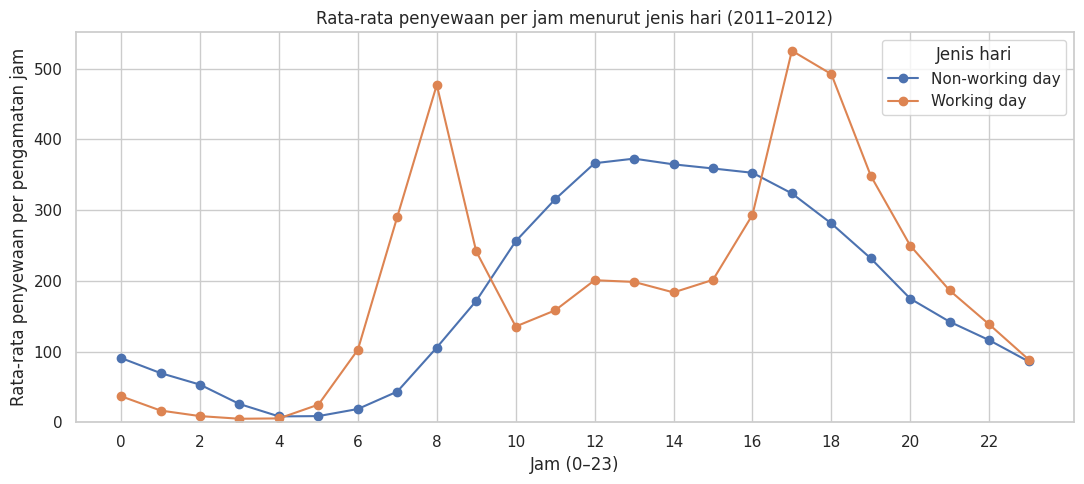

In [20]:
fig,ax=plt.subplots(figsize=(11,5))
for group,part in hourly_profile.groupby('day_type'):
    ax.plot(part.hr,part.avg_rentals,marker='o',label=group)
ax.set(title='Rata-rata penyewaan per jam menurut jenis hari (2011–2012)',xlabel='Jam (0–23)',ylabel='Rata-rata penyewaan per pengamatan jam',xticks=range(0,24,2),ylim=(0,None))
ax.legend(title='Jenis hari');plt.tight_layout();plt.show()

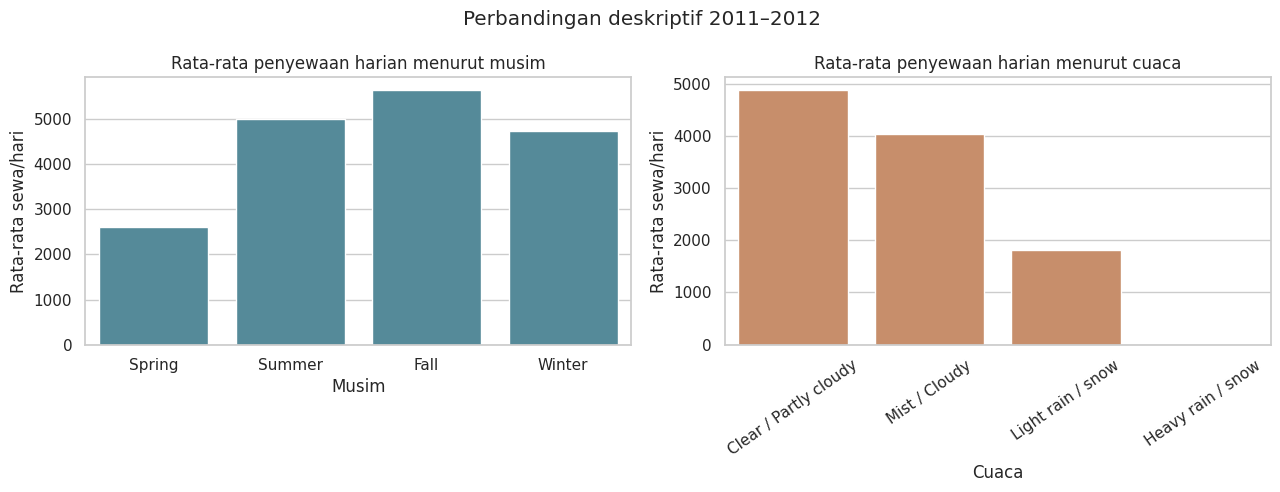

In [21]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
s_order=['Spring','Summer','Fall','Winter']
w_order=['Clear / Partly cloudy','Mist / Cloudy','Light rain / snow','Heavy rain / snow']
sns.barplot(data=season_profile,x='season_name',y='avg_daily_rentals',order=s_order,ax=axes[0],color='#4A90A4',errorbar=None)
axes[0].set(title='Rata-rata penyewaan harian menurut musim',xlabel='Musim',ylabel='Rata-rata sewa/hari',ylim=(0,None))
sns.barplot(data=weather_profile,x='weather_name',y='avg_daily_rentals',order=w_order,ax=axes[1],color='#D68B5C',errorbar=None)
axes[1].set(title='Rata-rata penyewaan harian menurut cuaca',xlabel='Cuaca',ylabel='Rata-rata sewa/hari',ylim=(0,None))
axes[1].tick_params(axis='x',rotation=35)
plt.suptitle('Perbandingan deskriptif 2011–2012');plt.tight_layout();plt.show()

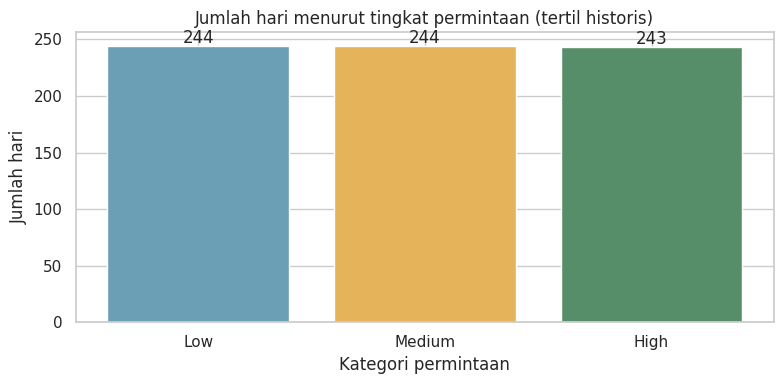

In [22]:
fig,ax=plt.subplots(figsize=(8,4))
counts=day_clean['demand_level'].value_counts().reindex(['Low','Medium','High'])
ax.bar(counts.index,counts.values,color=['#6A9FB5','#E4B35A','#568E69'])
ax.set(title='Jumlah hari menurut tingkat permintaan (tertil historis)',xlabel='Kategori permintaan',ylabel='Jumlah hari',ylim=(0,None))
for i,v in enumerate(counts.values):ax.text(i,v+3,str(int(v)),ha='center')
plt.tight_layout();plt.show()

## Conclusion & Recommendation

### Kesimpulan 1 — Pola penyewaan menurut jam dan jenis hari
Pada **hari kerja**, rata-rata penyewaan tertinggi muncul sekitar pukul **17.00** (525 sewa per pengamatan jam), kemudian **18.00** (492) dan **08.00** (477). Pada **hari non-kerja**, puncak rata-rata muncul sekitar **13.00** (373), diikuti **12.00** (366) dan **14.00** (365). Ini menunjukkan dua profil jam puncak yang berbeda. Angka merupakan rerata bersyarat pada jam yang memiliki observasi dalam dataset, bukan ramalan permintaan.

### Kesimpulan 2 — Musim dan cuaca
Rerata sewa harian paling tinggi pada **Fall** (5.644), paling rendah **Spring** (2.604). Kelompok cuaca **Clear / Partly cloudy** memiliki rata-rata tertinggi (4.877), sedangkan **Light rain / snow** lebih rendah (1.803). Perbedaan ini deskriptif dan dapat dipengaruhi faktor lain seperti musim, hari, dan tahun; analisis ini **tidak membuktikan cuaca sebagai penyebab**.

### Kesimpulan 3 — Kelompok permintaan
Pengelompokan berbasis tertil menghasilkan kategori **Low, Medium, High**, masing-masing merepresentasikan sekitar sepertiga hari yang diamati. Ambang berasal dari distribusi data 2011–2012, bukan target universal untuk tahun berikutnya.

### Action items
1. **Uji coba** penempatan sepeda/redistribusi operasional pada pukul 08.00 dan 17.00–18.00 di hari kerja, serta sekitar 12.00–14.00 pada hari non-kerja. Evaluasi realisasi transaksi dan kekurangan armada sebelum perubahan permanen.
2. Gunakan kalender musim dan prakiraan cuaca sebagai bahan **pemantauan kapasitas**, bukan dasar tunggal untuk keputusan; sertakan data operasi aktual.
3. Pantau hari *High demand* dengan ambang historis sebagai alat komunikasi internal; kalibrasi ulang bila pola waktu berubah.

### Keterbatasan
Dataset historis hanya 2011–2012, tanpa informasi kapasitas armada/stasiun, biaya, atau lokasi; observasi per jam juga tidak selalu lengkap untuk semua kombinasi tanggal-jam. Hasil tidak boleh dibaca sebagai klaim kausal atau proyeksi terkini.